# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [ ]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 2 — Upload the dataset

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/NaturalLanguageProcessingExperiments/Lab11/dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

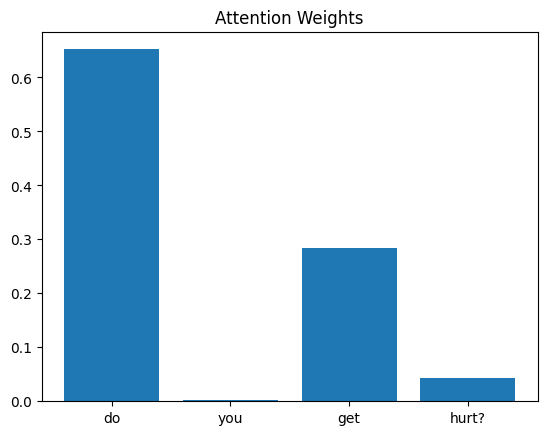

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

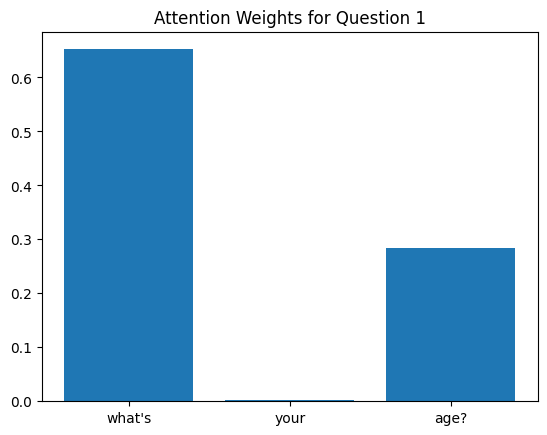

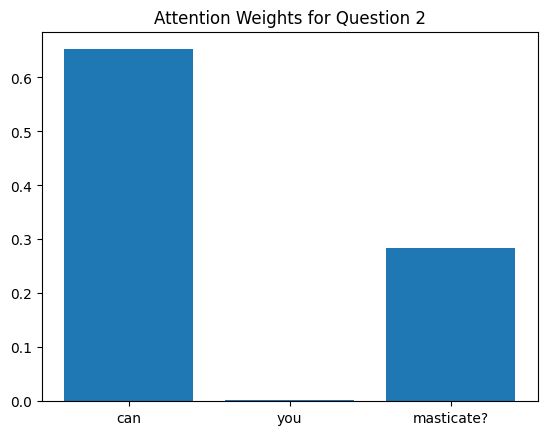

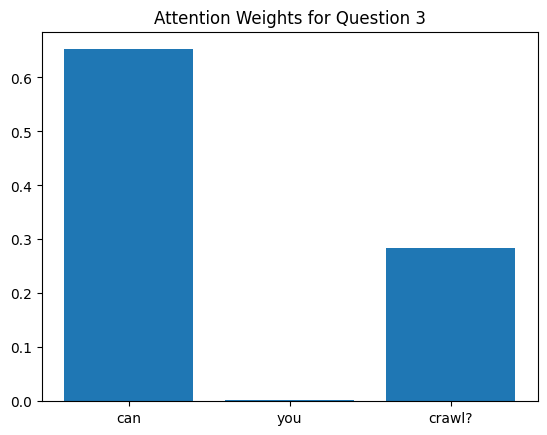

In [ ]:
#Selecting 3 questions from the dataset
question1 = df["question"][20]
question2 = df["question"][12]
question3 = df["question"][6]

#Building a bar chart for each question
words1 = question1.split()
words2 = question2.split()
words3 = question3.split()

with torch.no_grad():
    prediction1, weights1 = model(X[:1])
    prediction2, weights2 = model(X[:1])
    prediction3, weights3 = model(X[:1])
plt.bar(words1, weights1[0, :len(words1)].tolist())
plt.title("Attention Weights for Question 1")
plt.show()
plt.bar(words2, weights2[0, :len(words1)].tolist())
plt.title("Attention Weights for Question 2")
plt.show()
plt.bar(words3, weights3[0, :len(words1)].tolist())
plt.title("Attention Weights for Question 3")
plt.show()

*The word recieving the highest attention in question 1:* "What's"

*The word recieving the highest attention in question 2:* "can"

*The word recieveing the highest attention in question 3:* "can"

As for whether or not the word with the highest attention is important for understanding the question. The answer is: Yes it does, all three words with highest attention from the chosen questions are the question openers that indicate that this is a question to begin with, and the words with the second highest weights are what the question is about so it is also just as important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

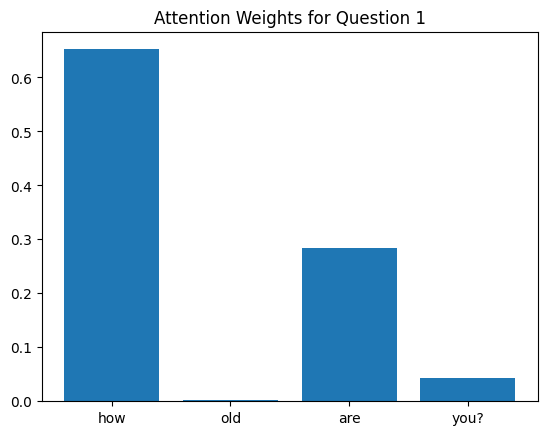

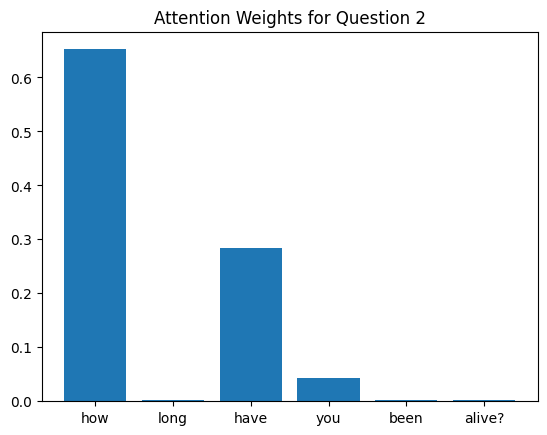

In [ ]:
#Selecting questions
question1= df["question"][24] #How old are you?
question2= df["question"][16] #How long have you been alive?

#Visualising the attention weights
words1 = question1.split()
words2 = question2.split()

with torch.no_grad():
    prediction1, weights1 = model(X[:1])
    prediction2, weights2 = model(X[:1])

plt.bar(words1, weights1[0, :len(words1)].tolist())
plt.title("Attention Weights for Question 1")
plt.show()
plt.bar(words2, weights2[0, :len(words2)].tolist())
plt.title("Attention Weights for Question 2")
plt.show()


The results suggest that the model learned to put more attention toward the question openers, as for both questions the word "how" recieved highest attention. That being said, the model did not focus on any other word that indicated the point of the question rather than the questions' openers.